# Plot Waveforms for ROMY Events

This notebook reads an event list file, loads data for each event, and creates a plot showing waveforms sorted by epicentral distance.

## Notebook Overview
This notebook generates multi-event waveform overview plots for ROMY analysis.

**Main workflow**
- Load events from list and associated configs.
- Read and preprocess waveform windows consistently.
- Build comparable waveform panels across events/channels.
- Annotate key timing and event information.
- Save overview waveform figures.

In [1]:
import os
import yaml
import numpy as np
import matplotlib.pyplot as plt
from obspy import UTCDateTime
from sixdegrees.sixdegrees import sixdegrees

## Configuration

In [2]:
# Path to event list file
events_list_file = "./events_list.yml"

# Component to plot (e.g., 'JZ', 'HZ', 'BJZ', etc.)
component = 'JZ'

# Output directory for figures
output_dir = "./output/figures/waveforms"
os.makedirs(output_dir, exist_ok=True)

## Load Event List

In [3]:
# Load events from YAML file
with open(events_list_file, 'r') as f:
    events_config = yaml.safe_load(f)
    events_list = events_config.get('events', [])

print(f"Found {len(events_list)} events in {events_list_file}")
print(f"Events: {events_list}")

Found 19 events in ./events_list.yml
Events: ['20190514', '20230908', '20230912', '20231202', '20240314', '20240322', '20240323', '20240414', '20240422', '20240815', '20240915', '20241023', '20250513', '20250602', '20251206', '20251212', '20251227', '20260107', '20260420']


## Load Data and Get Event Information

In [4]:
# Store data for each event
event_data_list = []

for date in events_list:
    print(f"\n{'='*60}")
    print(f"Processing event: {date}")
    print(f"{'='*60}")
    
    try:
        # Try config_romy_<date>.yml first, then config_<date>.yml
        config_path = f"./events/event_{date}/config_romy_{date}.yml"
        if not os.path.exists(config_path):
            config_path = f"./events/event_{date}/config_{date}.yml"
        
        if not os.path.exists(config_path):
            print(f"Warning: Config file not found for event {date}")
            continue
            
        # Load configuration
        config = sixdegrees.load_from_yaml(config_path)
        
        # Setup sixdegrees object
        sd = sixdegrees(conf=config)
        
        # Get event information
        ev = sd.get_event_info(
            origin_time=config['origin_time'],
            base_catalog="USGS",
            magnitude=config['magnitude']
        )
        
        print(f"Event: {ev.get('origin_time', 'N/A')}")
        print(f"Distance: {ev.get('distance_km', 'N/A'):.2f} km")
        print(f"Theoretical backazimuth: {ev.get('backazimuth', 'N/A'):.2f}°")
        
        # Load data
        sd.load_data(config['tbeg'], config['tend'], resample_rate=5)
        
        # Ensure all traces have the same amount of samples
        sd.trim_stream(set_common=True, set_interpolate=False)
        
        # Filter data
        sd.filter_data(fmin=config['fmin'], fmax=config['fmax'], output=False)
        # sd.filter_data(fmin=0.01, fmax=0.3, output=False)

        # Apply polarity correction if needed
        if 'pol_dict' in config:
            sd.polarity_stream(pol_dict=config['pol_dict'], raw=True)
        else:
            # Default polarity correction
            sd.polarity_stream(pol_dict={"HZ": -1, "JZ": 1}, raw=True)
        
        # Cut bad data if specified
        if 'time_cuts' in config:
            for key, values in config['time_cuts'].items():
                for value in values:
                    sd.replace_values_in_window(
                        tbeg=value[0], tend=value[1], 
                        value=0, channel_list=[key]
                    )
        
        # Get the waveform data for the specified component
        # Special handling for JT component: rotate NE to RT
        if component == 'JT':
            # Check if we have JN and JE components
            rot_n = sd.st.select(channel="*JN")
            rot_e = sd.st.select(channel="*JE")
            
            if len(rot_n) == 0 or len(rot_e) == 0:
                print(f"Warning: Missing JN or JE components for rotation to JT")
                continue
            
            # Create a copy of the stream with horizontal rotation components for rotation
            rot_h_ne = sd.st.copy().select(channel="*J*")
            
            # Get backazimuth for rotation
            baz_theo = ev.get('backazimuth', None)
            if baz_theo is None:
                print(f"Warning: No backazimuth found for event {date}, cannot rotate to JT")
                continue
            
            # Rotate NE to RT
            rot_h_rt = rot_h_ne.copy()
            rot_h_rt.rotate('NE->RT', back_azimuth=baz_theo)
            
            # Select the T (Transverse) component
            stream = rot_h_rt.select(channel="*T")
            
            if len(stream) == 0:
                print(f"Warning: No T component found after rotation for event {date}")
                continue
        else:
            # For other components, use direct selection
            stream = sd.st.select(channel=f"*{component}")
        
        if len(stream) == 0:
            print(f"Warning: No data found for component {component}")
            continue
        
        # Get the first trace (should be only one for a specific component)
        trace = stream[0]
        
        # Get time array relative to origin time
        origin_time = UTCDateTime(config['origin_time'])
        times = (np.array(trace.times()) + (trace.stats.starttime - origin_time)) / 3600.0  # Convert to hours
        
        # Store event data
        event_data_list.append({
            'date': date,
            'distance_km': ev.get('distance_km', np.nan),
            'magnitude': config.get('magnitude', np.nan),
            'origin_time': origin_time,
            'times': times,
            'data': trace.data,
            'component': component,
            'sampling_rate': trace.stats.sampling_rate
        })
        
        print(f"Successfully loaded data for event {date}")
        
    except Exception as e:
        print(f"Error processing event {date}: {str(e)}")
        import traceback
        traceback.print_exc()
        continue

print(f"\n{'='*60}")
print(f"Successfully loaded {len(event_data_list)} events")
print(f"{'='*60}")


Processing event: 20190514
Found event:
Origin time: 2019-05-14T12:58:25.939000Z
Magnitude: 7.6 mww
Location: -4.051°N, 152.597°E
Depth: 10.0 km
Epicentral Distance: 13894.14 km
Epicentral Distance: 125.0°
Backazimuth: 49.29°
Event: 2019-05-14T12:58:25.939000Z
Distance: 13894.14 km
Theoretical backazimuth: 49.29°
-> fetching XX.ROMY..BHZ data from mseed file
-> fetching XX.ROMY..BHN data from mseed file
-> fetching XX.ROMY..BHE data from mseed file
3 Trace(s) in Stream:
XX.ROMY..BHZ | 2019-05-14T13:14:58.990000Z - 2019-05-14T14:30:00.990000Z | 20.0 Hz, 90041 samples
XX.ROMY..BHN | 2019-05-14T13:14:58.990000Z - 2019-05-14T14:30:00.990000Z | 20.0 Hz, 90041 samples
XX.ROMY..BHE | 2019-05-14T13:14:58.990000Z - 2019-05-14T14:30:00.990000Z | 20.0 Hz, 90041 samples
-> fetching XX.ROMY..BJZ data from mseed file
-> fetching XX.ROMY..BJN data from mseed file
-> fetching XX.ROMY..BJE data from mseed file
3 Trace(s) in Stream:
XX.ROMY..BJZ | 2019-05-14T13:14:59.010599Z - 2019-05-14T14:30:01.01059

In [5]:
# Sort events by distance (nearest first, so it appears on top)
event_data_list_sorted = sorted(event_data_list, key=lambda x: x['distance_km'])

print("Events sorted by distance (nearest to farthest):")
for i, event_data in enumerate(event_data_list_sorted):
    print(f"  {i+1}. Event {event_data['date']}: {event_data['distance_km']:.2f} km")

Events sorted by distance (nearest to farthest):
  1. Event 20250602: 1876.52 km
  2. Event 20250513: 1934.89 km
  3. Event 20230908: 2526.01 km
  4. Event 20240314: 4977.44 km
  5. Event 20251206: 7693.73 km
  6. Event 20240915: 8369.87 km
  7. Event 20241023: 8666.62 km
  8. Event 20251212: 9050.67 km
  9. Event 20260420: 9144.40 km
  10. Event 20251227: 9410.60 km
  11. Event 20240422: 9470.32 km
  12. Event 20240815: 9474.15 km
  13. Event 20230912: 9828.37 km
  14. Event 20231202: 11105.49 km
  15. Event 20260107: 11249.87 km
  16. Event 20240322: 11316.56 km
  17. Event 20240323: 13331.88 km
  18. Event 20190514: 13894.14 km
  19. Event 20240414: 13978.50 km


## Plot Waveforms

Saved: ./output/figures/waveforms_JZ_by_distance.png


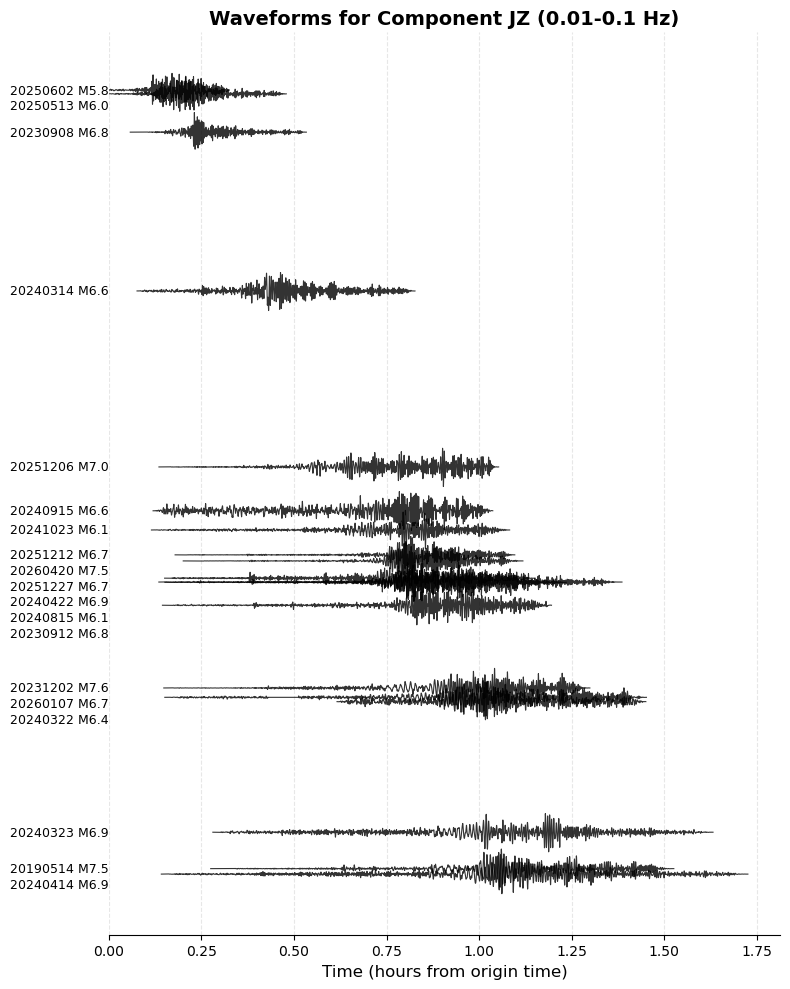

In [6]:
if len(event_data_list_sorted) > 0:
    fig, ax = plt.subplots(figsize=(8, 10))
    
    # Amplitude scaling mode:
    # - 'trace': each trace scaled by its own peak amplitude
    # - 'peak': all traces scaled by the global peak amplitude
    amplitude_scaling_mode = 'trace'  # change to 'peak' to use global peak scaling

    # Calculate normalization factor based on distance range
    distances = [ed['distance_km'] for ed in event_data_list_sorted]
    min_dist = min(distances)
    max_dist = max(distances)
    dist_range = max_dist - min_dist

    # Use a fraction of the distance range so neighboring traces do not overlap heavily
    normalization_factor = dist_range * 0.025 if dist_range > 0 else 0.8

    trace_peaks = [np.max(np.abs(ed['data'])) for ed in event_data_list_sorted if len(ed['data']) > 0]
    global_peak = max(trace_peaks) if trace_peaks else 0.0

    # Keep text labels readable even for very close distances
    min_label_gap = max(dist_range * 0.02, 80.0)
    placed_label_positions = []

    # Plot each event
    for event_data in event_data_list_sorted:
        times = event_data['times']
        data = event_data['data']
        distance = event_data['distance_km']
        date = event_data['date']
        magnitude = event_data['magnitude']

        if len(data) > 0:
            trace_peak = np.max(np.abs(data))

            if amplitude_scaling_mode == 'peak':
                denom = global_peak
            else:
                denom = trace_peak

            if denom > 0:
                normalized_data = (data / denom) * normalization_factor
            else:
                normalized_data = data

            # Offset for y-axis (distance): nearest on top after y-axis inversion
            y_offset = distance

            # Plot the waveform in black
            ax.plot(times, normalized_data + y_offset,
                    linewidth=0.8, alpha=0.8, color='black')

            # Add event date and magnitude label on the left with overlap prevention
            mag_str = f"{magnitude:.1f}" if not np.isnan(magnitude) else "N/A"
            label_y = y_offset
            if placed_label_positions and (label_y - placed_label_positions[-1]) < min_label_gap:
                label_y = placed_label_positions[-1] + min_label_gap
            placed_label_positions.append(label_y)

            ax.text(0, label_y, f"{date} M{mag_str}",
                    ha='right', va='center', fontsize=9, color='black')
    
    # Set labels and title
    ax.set_xlabel('Time (hours from origin time)', fontsize=12)
    # ax.set_ylabel('Epicentral Distance (km)', fontsize=12, fontweight='bold')
    ax.set_title(f"Waveforms for Component {component} ({config['fmin']}-{config['fmax']} Hz)", 
                fontsize=14, fontweight='bold')
    
    # ax.set_yscale('log')

    # Invert y-axis so nearest (smallest distance) is on top
    ax.invert_yaxis()
    
    ax.set_xlim(left=0)

    # Deactive y-axis
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Add grid
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.grid(True, alpha=0.1, which='minor', linestyle=':')
    
    # Adjust layout
    plt.tight_layout()
    
    # Save figure
    output_file = os.path.join(output_dir, f"waveforms_{component}_by_distance.png")
    plt.savefig(output_file, dpi=300, bbox_inches='tight')
    print(f"Saved: {output_file}")
    
    plt.show()
else:
    print("No data to plot!")

/tmp/ipykernel_5806/1915667911.py:28: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', max(n_events, 1))


Saved: ./output/figures/waveforms_JZ_by_distance_colored_deg.png


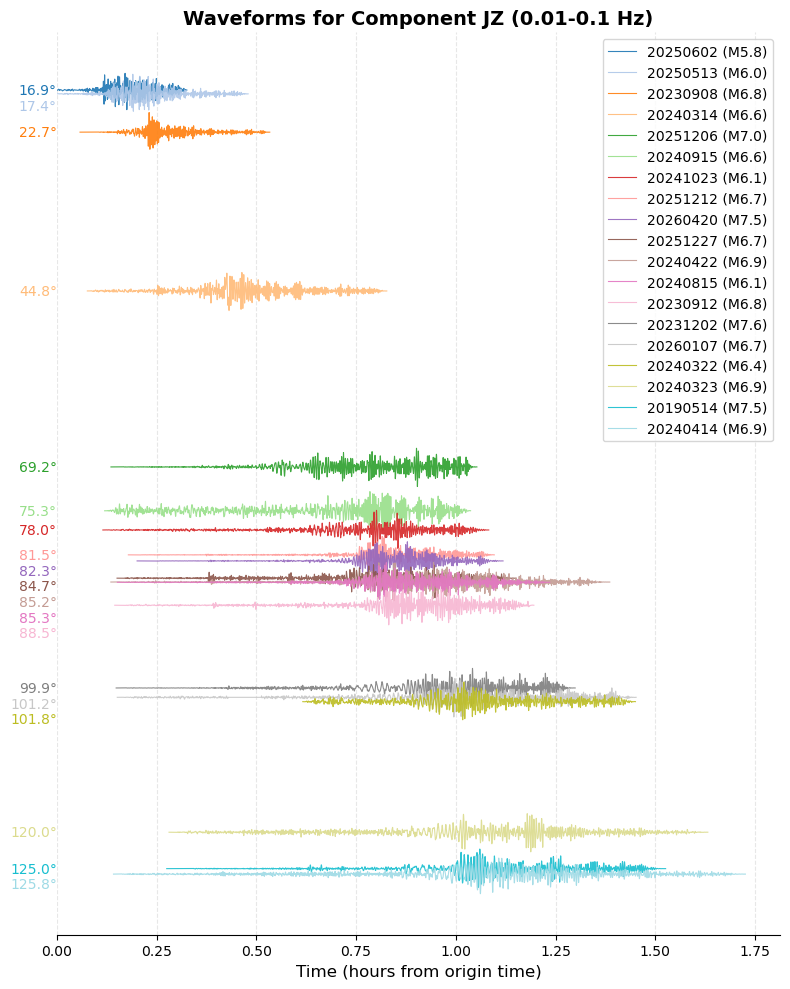

In [7]:
# Copy of waveform plot: unique event colors + distance labels in degrees
if len(event_data_list_sorted) > 0:
    fig, ax = plt.subplots(figsize=(8, 10))

    # Amplitude scaling mode:
    # - 'trace': each trace scaled by its own peak amplitude
    # - 'peak': all traces scaled by the global peak amplitude
    amplitude_scaling_mode = 'trace'  # change to 'peak' to use global peak scaling

    # Calculate normalization factor based on distance range
    distances = [ed['distance_km'] for ed in event_data_list_sorted]
    min_dist = min(distances)
    max_dist = max(distances)
    dist_range = max_dist - min_dist

    # Use a fraction of the distance range so neighboring traces do not overlap heavily
    normalization_factor = dist_range * 0.025 if dist_range > 0 else 0.8

    trace_peaks = [np.max(np.abs(ed['data'])) for ed in event_data_list_sorted if len(ed['data']) > 0]
    global_peak = max(trace_peaks) if trace_peaks else 0.0

    # Keep text labels readable even for very close distances
    min_label_gap = max(dist_range * 0.02, 80.0)
    placed_label_positions = []

    # Assign one unique color per event
    n_events = len(event_data_list_sorted)
    cmap = plt.cm.get_cmap('tab20', max(n_events, 1))
    event_colors = [cmap(i) for i in range(n_events)]

    # Collect legend handles and labels (event/date + magnitude)
    legend_handles = []
    legend_labels = []

    # Plot each event
    for i, event_data in enumerate(event_data_list_sorted):
        times = event_data['times']
        data = event_data['data']
        distance = event_data['distance_km']
        date = event_data.get('date', event_data.get('event', f'Event {i+1}'))
        magnitude = event_data.get('magnitude', np.nan)

        if len(data) > 0:
            trace_peak = np.max(np.abs(data))

            if amplitude_scaling_mode == 'peak':
                denom = global_peak
            else:
                denom = trace_peak

            if denom > 0:
                normalized_data = (data / denom) * normalization_factor
            else:
                normalized_data = data

            # Offset for y-axis (distance): nearest on top after y-axis inversion
            y_offset = distance

            # Plot waveform with a unique event color
            line, = ax.plot(times, normalized_data + y_offset,
                            linewidth=0.8, alpha=0.9, color=event_colors[i])

            # Add legend entry with event/date + magnitude
            mag_str = f"M{magnitude:.1f}" if not np.isnan(magnitude) else "M N/A"
            legend_handles.append(line)
            legend_labels.append(f"{date} ({mag_str})")

            # Label with epicentral distance in degrees
            distance_deg = event_data.get('distance_deg', round(distance * 180/20_000, 1))
            label_y = y_offset
            if placed_label_positions and (label_y - placed_label_positions[-1]) < min_label_gap:
                label_y = placed_label_positions[-1] + min_label_gap
            placed_label_positions.append(label_y)

            ax.text(0, label_y, f"{distance_deg:.1f}°",
                    ha='right', va='center', fontsize=10, color=event_colors[i])

    # Set labels and title
    ax.set_xlabel('Time (hours from origin time)', fontsize=12)
    ax.set_title(f"Waveforms for Component {component} ({config['fmin']}-{config['fmax']} Hz)", 
                 fontsize=14, fontweight='bold')

    # Invert y-axis so nearest (smallest distance) is on top
    ax.invert_yaxis()

    ax.set_xlim(left=0)

    # Deactivate y-axis
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Add legend at top-right
    if legend_handles:
        ax.legend(legend_handles, legend_labels, loc='upper right', fontsize=10, frameon=True)

    # Add grid
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.grid(True, alpha=0.1, which='minor', linestyle=':')

    # Adjust layout
    plt.tight_layout()

    # Save figure
    output_file = os.path.join(output_dir, f"waveforms_{component}_by_distance_colored_deg.png")
    plt.savefig(output_file, dpi=300, bbox_inches='tight')
    print(f"Saved: {output_file}")

    plt.show()
else:
    print("No data to plot!")

## Plot Waveforms in Grid Layout

Saved: ./output/figures/waveforms_JZ_grid.png


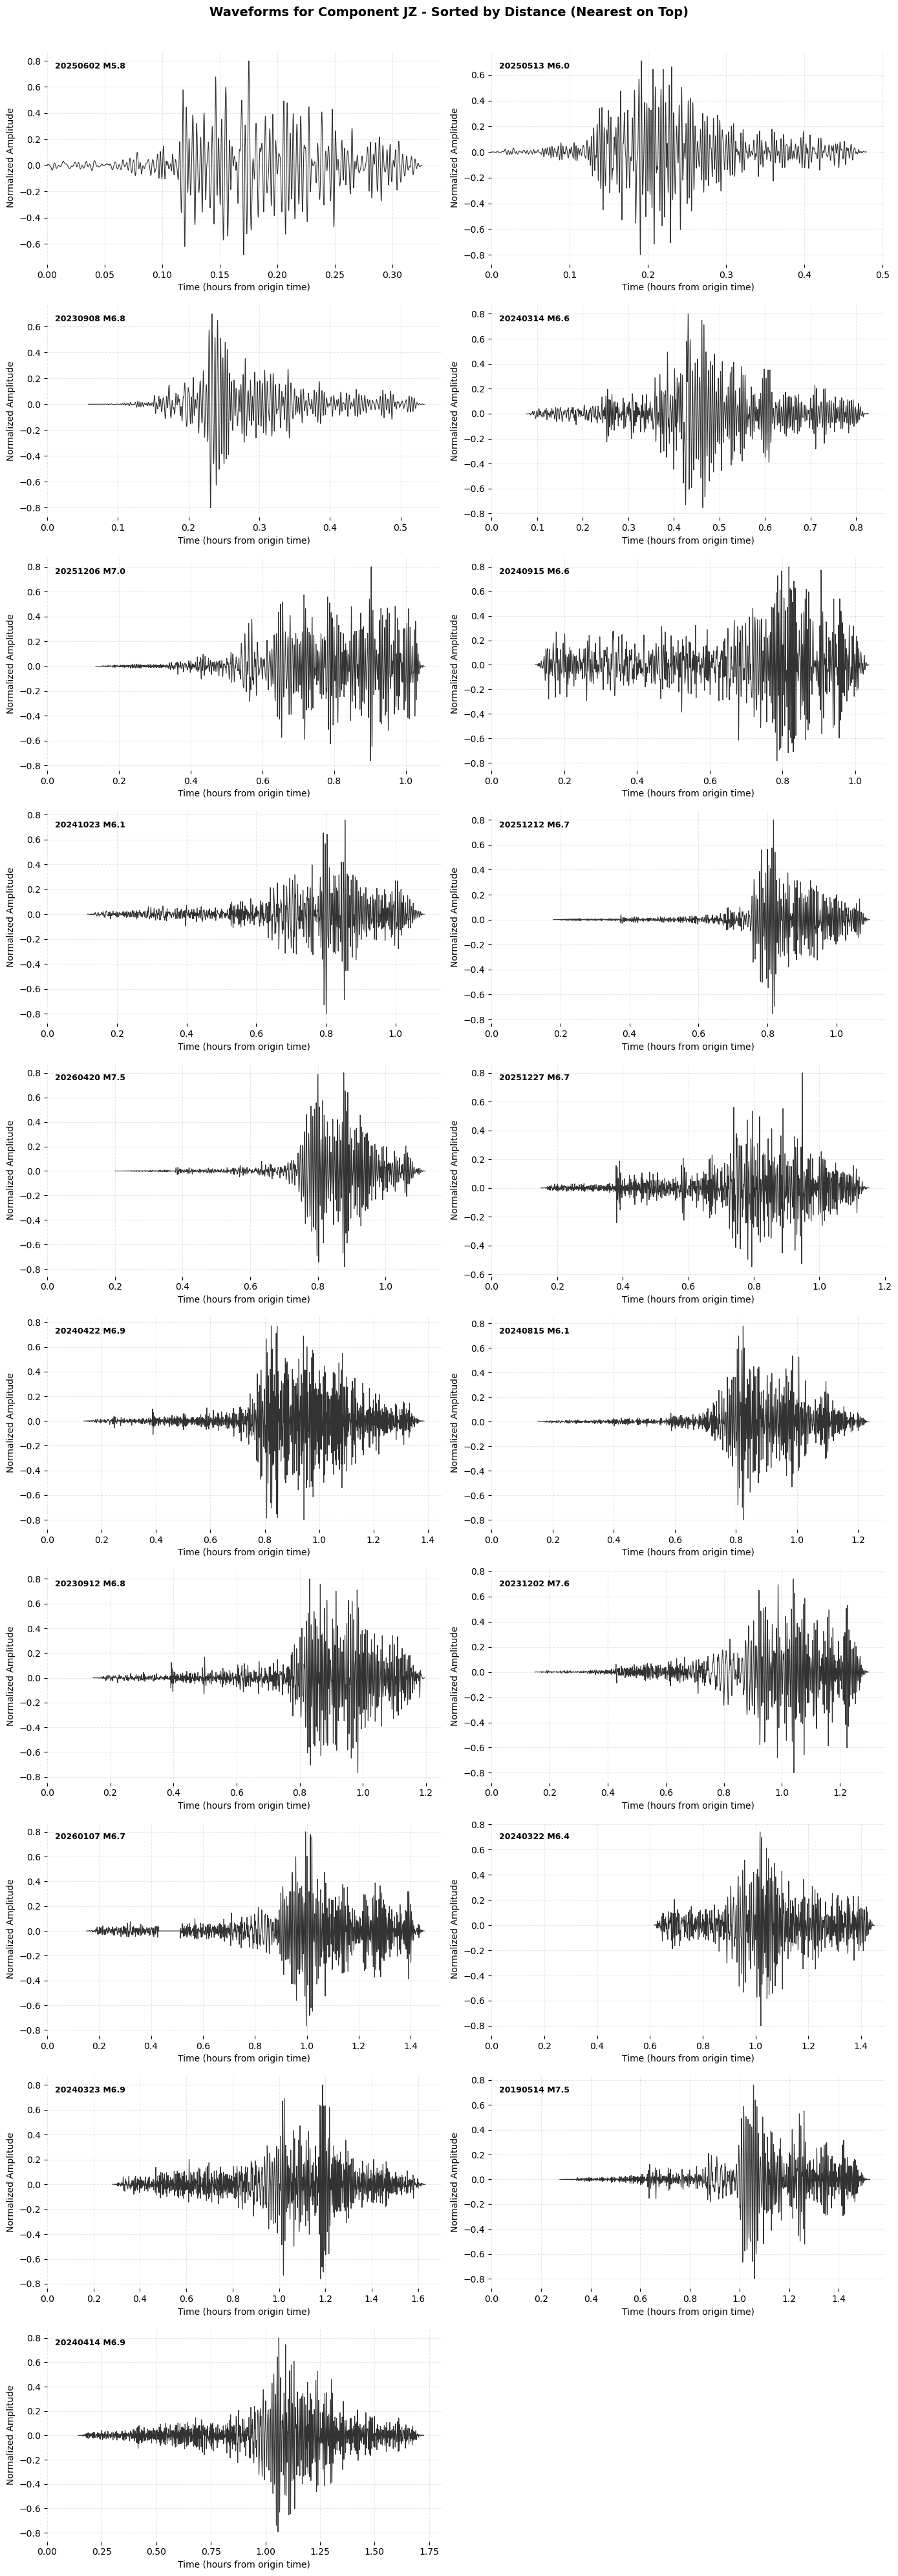

In [8]:
if len(event_data_list_sorted) > 0:
    # Calculate number of rows needed (2 columns)
    n_events = len(event_data_list_sorted)
    n_cols = 2
    n_rows = int(np.ceil(n_events / n_cols))
    
    # Create figure with subplots
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
    
    # Flatten axes array for easier indexing
    if n_rows == 1:
        axes = axes.reshape(1, -1)
    axes_flat = axes.flatten()
    
    # Normalization factor for each trace
    normalization_factor = 0.8
    
    # Plot each event in its own subplot
    for i, event_data in enumerate(event_data_list_sorted):
        ax = axes_flat[i]
        
        times = event_data['times']
        data = event_data['data']
        distance = event_data['distance_km']
        date = event_data['date']
        magnitude = event_data['magnitude']
        
        # Normalize the data
        if len(data) > 0:
            max_amp = np.max(np.abs(data))
            if max_amp > 0:
                normalized_data = (data / max_amp) * normalization_factor
            else:
                normalized_data = data
            
            # Plot the waveform in black
            ax.plot(times, normalized_data, linewidth=0.8, alpha=0.8, color='black')
            
            # Add event date and magnitude label
            mag_str = f"{magnitude:.1f}" if not np.isnan(magnitude) else "N/A"
            ax.text(0.02, 0.95, f"{date} M{mag_str}", 
                   transform=ax.transAxes,
                   ha='left', va='top', fontsize=9, fontweight='bold', color='black')
        
        # Set labels
        ax.set_xlabel('Time (hours from origin time)', fontsize=10)
        ax.set_ylabel('Normalized Amplitude', fontsize=10)
        
        # Remove frame (spines)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        
        # Set x-axis limit
        ax.set_xlim(left=0)
        
        # Add grid
        ax.grid(True, alpha=0.3, linestyle='--')
        ax.grid(True, alpha=0.1, which='minor', linestyle=':')
    
    # Hide unused subplots
    for i in range(n_events, len(axes_flat)):
        axes_flat[i].set_visible(False)
    
    # Set overall title
    fig.suptitle(f'Waveforms for Component {component} - Sorted by Distance (Nearest on Top)', 
                fontsize=14, fontweight='bold', y=0.995)
    
    # Adjust layout
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    
    # Save figure
    output_file = os.path.join(output_dir, f"waveforms_{component}_grid.png")
    plt.savefig(output_file, dpi=300, bbox_inches='tight')
    print(f"Saved: {output_file}")
    
    plt.show()
else:
    print("No data to plot!")